# Avance 4. Modelos alternativos

**TC5035 Proyecto Integrador · Equipo 56**

Sistema Inteligente para la Optimización de Operaciones de Transporte mediante Inteligencia Artificial aplicada al Análisis Predictivo de Datos GPS (Feraltar).

| Integrante | Matrícula |
|---|---|
| Alejandra Guadalupe Larrañaga Altamirano | A01794334 |
| Mario Alberto Guillén | A01796701 |
| Andrea Kimberly Fray Tamayo | A01797168 |

**Objetivo de este avance:** construir al menos seis modelos individuales (no ensambles) con algoritmos variados para predecir la duración del viaje (`duration_seconds`), compararlos con un protocolo común, ajustar los hiperparámetros de los dos mejores y elegir el modelo individual final.

**Punto de partida (Avance 3).** El baseline de regresión lineal con Lasso obtuvo un MAE de 7.9 min en prueba, con 70 % de los viajes dentro de ±10 min. No sobreajusta, pero subajusta: los residuos muestran una relación no lineal con la distancia que una recta no captura. Los modelos de este avance buscan resolver ese subajuste.

**Contenido**
1. Configuración
2. Carga de la partición del Avance 2
3. Protocolo de evaluación
4. Referencias del Avance 3
5. Modelos alternativos
6. Tabla comparativa
7. Selección de los dos mejores modelos
8. Ajuste fino de hiperparámetros
9. Modelo individual final
10. Conclusiones
11. Bibliografía
12. Declaración sobre el uso de herramientas de inteligencia artificial

## 1. Configuración

In [3]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)

SEMILLA = 42
OBJETIVO = "duration_seconds"
COLUMNA_DISTANCIA = "distance_km"

np.random.seed(SEMILLA)

## 2. Carga de la partición del Avance 2

Se usa la misma partición de entrenamiento y prueba exportada en el Avance 2 y usada en el Avance 3, para que todos los modelos se comparen sobre exactamente los mismos viajes.

In [5]:
def encontrar_raiz(inicio: Path) -> Path:
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "processed").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la carpeta data/processed en el repositorio.")


RAIZ = encontrar_raiz(Path.cwd())
PROCESADOS = RAIZ / "data" / "processed"
SUFIJO = "avance2.csv.gz"


def leer_y(nombre: str) -> pd.Series:
    datos = pd.read_csv(PROCESADOS / nombre)
    assert datos.shape[1] == 1, f"{nombre} debería tener una sola columna y tiene {datos.shape[1]}"
    return datos.iloc[:, 0]


X_train = pd.read_csv(PROCESADOS / f"X_train_{SUFIJO}")
X_test = pd.read_csv(PROCESADOS / f"X_test_{SUFIJO}")
y_train = leer_y(f"y_train_{SUFIJO}")
y_test = leer_y(f"y_test_{SUFIJO}")

assert y_train.name == OBJETIVO
assert list(X_train.columns) == list(X_test.columns)

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Características: {X_train.shape[1]}")

X_train: (349445, 59) | X_test: (87362, 59)
Características: 59


## 3. Protocolo de evaluación

Para que la comparación sea justa, **todos los modelos se entrenan y evalúan con la misma función `registrar`**, que:

1. Entrena el modelo con el conjunto de entrenamiento y mide el **tiempo de entrenamiento**.
2. Predice el conjunto de prueba completo y mide el **tiempo de predicción**.
3. Calcula las métricas en entrenamiento y prueba, y guarda una fila en `resultados`.

**Métricas** (las mismas del Avance 3):

- **MAE en minutos, métrica principal.** Error promedio del ETA; la tabla comparativa se ordena por esta métrica.
- **RMSE en minutos.** Penaliza más los errores grandes, que son los más costosos para operaciones.
- **R².** Proporción de la variación de la duración explicada por el modelo.
- **% de viajes dentro de ±10 y ±15 min.** Lectura operativa del error.
- **Brecha de MAE (prueba menos entrenamiento).** Señal de sobreajuste.

**Modelos lentos.** Algunos algoritmos (por ejemplo SVR con kernel o KNN) escalan mal con 350 mil viajes. Para ellos se puede entrenar con una muestra usando `n_entrenamiento`; la evaluación **siempre** se hace sobre el conjunto de prueba completo, y la tabla registra cuántos viajes se usaron para entrenar.

In [7]:
resultados = []


def registrar(nombre, modelo, n_entrenamiento=None, columnas=None):
    """Entrena, mide tiempos y guarda las métricas de un modelo.

    nombre:          nombre del modelo en la tabla comparativa.
    modelo:          estimador de scikit-learn (o Pipeline) sin entrenar.
    n_entrenamiento: si se indica, entrena con una muestra aleatoria de ese tamaño.
    columnas:        si se indica, usa solo esas columnas (por defecto, las 59).
    """
    X_tr, y_tr = X_train, y_train
    if n_entrenamiento is not None and n_entrenamiento < len(X_train):
        idx = X_train.sample(n_entrenamiento, random_state=SEMILLA).index
        X_tr, y_tr = X_train.loc[idx], y_train.loc[idx]
    X_te = X_test
    if columnas is not None:
        X_tr, X_te = X_tr[columnas], X_te[columnas]

    inicio = time.perf_counter()
    modelo.fit(X_tr, y_tr)
    t_entrenamiento = time.perf_counter() - inicio

    inicio = time.perf_counter()
    pred_test = modelo.predict(X_te)
    t_prediccion = time.perf_counter() - inicio
    pred_train = modelo.predict(X_tr)

    error_test = np.abs(y_test.values - pred_test) / 60
    fila = {
        "modelo": nombre,
        "MAE_min": error_test.mean(),
        "RMSE_min": np.sqrt(mean_squared_error(y_test, pred_test)) / 60,
        "R2": r2_score(y_test, pred_test),
        "dentro_10min_%": (error_test <= 10).mean() * 100,
        "dentro_15min_%": (error_test <= 15).mean() * 100,
        "MAE_train_min": mean_absolute_error(y_tr, pred_train) / 60,
        "t_entrenamiento_s": t_entrenamiento,
        "t_prediccion_s": t_prediccion,
        "n_entrenamiento": len(X_tr),
    }
    fila["brecha_MAE_min"] = fila["MAE_min"] - fila["MAE_train_min"]

    resultados[:] = [r for r in resultados if r["modelo"] != nombre]
    resultados.append(fila)
    return pd.Series(fila).drop("modelo").round(3)

## 4. Referencias del Avance 3

Se vuelven a entrenar los dos modelos de referencia para que aparezcan en la tabla con sus tiempos:

- **Dummy (mediana):** piso, sin usar características.
- **Lasso (baseline del Avance 3):** con el `alpha` elegido por validación cruzada en el Avance 3 (0.001). Es el desempeño mínimo que deben superar los modelos alternativos.

Ninguno de los dos cuenta entre los seis modelos alternativos.

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso

registrar("Ref. Dummy (mediana)", DummyRegressor(strategy="median"))
registrar("Ref. Lasso (baseline Avance 3)", Lasso(alpha=0.001, max_iter=2000, tol=1e-3))
pd.DataFrame(resultados).set_index("modelo")[["MAE_min", "RMSE_min", "R2", "dentro_10min_%", "t_entrenamiento_s"]].round(3)

,MAE_min,RMSE_min,R2,dentro_10min_%,t_entrenamiento_s
modelo,,,,,
Ref. Dummy (mediana),59.602,77.223,-0.050,9.630,0.002
Ref. Lasso (baseline Avance 3),7.934,10.273,0.981,70.298,3.962


## 5. Modelos alternativos

Se construyen seis modelos individuales con algoritmos de familias distintas. Todos usan la función `registrar` con sus hiperparámetros por defecto o razonables; el ajuste fino se hace en la sección 8 solo para los dos mejores.

| # | Modelo | Familia | Por qué se incluye |
|---|---|---|---|
| 5.1 | Regresión polinomial con Ridge | Lineal con transformación | Captura la curvatura entre distancia y duración que el baseline no modela |
| 5.2 | Árbol de decisión | Árboles | No lineal, interpretable y capta interacciones entre zona, hora y distancia |
| 5.3 | K vecinos más cercanos (KNN) | Basado en instancias | Predice con viajes parecidos; no supone ninguna forma funcional |
| 5.4 | Máquina de soporte vectorial (LinearSVR) | Máquinas de soporte vectorial | Ajusta la duración con un margen de tolerancia al error; se usa la versión lineal por el tamaño de los datos |
| 5.5 | Red neuronal (MLP) | Redes neuronales | Aprende relaciones no lineales e interacciones complejas |
| 5.6 | Regresión robusta Huber | Lineal robusta | Reduce la influencia de los viajes con errores grandes |



### 5.1 Regresión polinomial con Ridge

Agregamos términos polinomiales de grado 3 solo a las variables continuas (distancia, hora y día en forma cíclica) y usamos Ridge con `alpha=1.0` para que esos términos no se disparen. Se entrenó con los 349,445 viajes.

Obtuvo un MAE de 5.98 min, 25 % menos que el baseline, con 82.4 % de viajes dentro de ±10 min y una brecha de 0.25 min. Ayuda a captar la curva con la distancia, pero se queda corto frente a los modelos no lineales.

In [12]:
# 5.1 Regresión polinomial con Ridge
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

CONTINUAS = ["distance_km", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]

def crear_polinomial(grado=3, alpha=1.0):
    terminos = Pipeline([
        ("polinomio", PolynomialFeatures(degree=grado, include_bias=False)),
        ("escala", StandardScaler()),
    ])
    # Solo a las continuas: elevar al cuadrado una columna 0/1 de zona no agrega nada
    preparacion = ColumnTransformer([("continuas", terminos, CONTINUAS)], remainder="passthrough")
    return Pipeline([("preparacion", preparacion), ("ridge", Ridge(alpha=alpha))])

registrar("Regresión polinomial (grado 3) + Ridge", crear_polinomial())

MAE_min               5.978955
RMSE_min              7.964852
R2                    0.988831
dentro_10min_%       82.414551
dentro_15min_%       92.611204
MAE_train_min         5.726173
t_entrenamiento_s     0.442925
t_prediccion_s        0.052136
n_entrenamiento         349445
brecha_MAE_min        0.252781
dtype: object

### 5.2 Árbol de decisión

Usamos `max_depth=16` y `min_samples_leaf=15` para que el árbol no se aprenda viajes sueltos. Como va partiendo los datos por distancia, zona y hora, puede captar combinaciones entre ellas.

MAE de 3.90 min (51 % menos que el baseline) y 93.3 % dentro de ±10 min. Es el que predice más rápido (alrededor de 0.01 s para los 87 mil viajes de prueba). La brecha de 0.87 min muestra algo de sobreajuste, pero no mucho.

In [14]:
from sklearn.tree import DecisionTreeRegressor
registrar("DecisionTreeRegressor", DecisionTreeRegressor(max_depth = 16,min_samples_leaf=15, random_state = SEMILLA))

MAE_min               3.902613
RMSE_min              5.201589
R2                    0.995237
dentro_10min_%       93.333486
dentro_15min_%       99.043062
MAE_train_min          3.03161
t_entrenamiento_s     0.777488
t_prediccion_s        0.012307
n_entrenamiento         349445
brecha_MAE_min        0.871004
dtype: object

### 5.3 K vecinos más cercanos (KNN)

Lo dejamos con los valores por defecto (`n_neighbors=5`, pesos uniformes, distancia euclidiana). Para cada viaje busca los 5 más parecidos en entrenamiento y promedia su duración. Por eso "entrenar" casi no tarda, solo guarda los datos. 

Quedó segundo, con MAE de 3.62 min y 94.0 % dentro de ±10 min. Lo malo es que tarda unos 11 s en predecir el conjunto de prueba, cerca de 900 veces más que el árbol.

In [16]:
from sklearn.neighbors import KNeighborsRegressor
registrar("KNeighborsRegressor", KNeighborsRegressor())

MAE_min                3.62285
RMSE_min               4.99624
R2                    0.995605
dentro_10min_%       94.006547
dentro_15min_%       98.790092
MAE_train_min          2.86913
t_entrenamiento_s     0.040482
t_prediccion_s       10.950136
n_entrenamiento         349445
brecha_MAE_min         0.75372
dtype: object

### 5.4 Máquina de soporte vectorial (SVR)

Usamos `LinearSVR` (`C=1.0`, `epsilon=0.1`, con las variables estandarizadas) en vez de SVR con kernel, porque con 350 mil viajes el kernel RBF tarda demasiado. Por lo mismo lo entrenamos con una muestra de **50,000 viajes** (`n_entrenamiento=50000`) y lo evaluamos con todo el conjunto de prueba.

Sacó un MAE de 8.24 min, incluso peor que el baseline. Como también es lineal, tiene el mismo problema de subajuste; la brecha de 0.05 min dice que no es sobreajuste.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVR

# Pipeline para escalar las variables y entrenar el modelo SVR
linear_svr = Pipeline([

    # Estandariza las variables para mejorar el desempeño de SVM
    ("scaler", StandardScaler()),

    # Versión lineal de SVR, más eficiente para conjuntos de datos grandes
    ("svr", LinearSVR(
        C=1.0,
        epsilon=0.1,
        max_iter=5000,
        random_state=SEMILLA
    ))
])

# Entrenamiento solo con una muestra
registrar(
    "LinearSVR",
    linear_svr,
    n_entrenamiento=50000
)

MAE_min               8.242595
RMSE_min             11.214843
R2                    0.977857
dentro_10min_%       71.048053
dentro_15min_%       84.185344
MAE_train_min         8.193602
t_entrenamiento_s     0.086037
t_prediccion_s        0.011156
n_entrenamiento          50000
brecha_MAE_min        0.048994
dtype: object

### 5.5 Red neuronal (MLP)

Red con dos capas ocultas de 64 y 32 neuronas, ReLU, `alpha=1e-4` y tasa de aprendizaje de `1e-3` (Adam). Activamos `early_stopping`, que la detuvo en 17 épocas, y estandarizamos el objetivo con `TransformedTargetRegressor` porque en segundos la red no convergía bien.

Fue la mejor: MAE de 3.52 min y 96.1 % dentro de ±10 min. Tarda más en entrenar (unos 20 s), pero predice rápido (0.03 s). Tiene la brecha más alta (1.02 min), por eso en el ajuste fino también movemos la regularización.

In [20]:
# 5.5 Red neuronal MLP
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor

def crear_mlp(capas=(64, 32), activacion="relu", alpha=1e-4, tasa=1e-3):
    red = MLPRegressor(hidden_layer_sizes=capas, activation=activacion, alpha=alpha,
                       learning_rate_init=tasa, early_stopping=True,
                       max_iter=200, random_state=SEMILLA)
    # El objetivo está en segundos; la red converge mejor si se estandariza
    return TransformedTargetRegressor(regressor=red, transformer=StandardScaler())

mlp = crear_mlp()
registrar("Red neuronal MLP (64, 32)", mlp)
print("Épocas:", mlp.regressor_.n_iter_)

Épocas: 17


### 5.6 Regresión robusta Huber

`HuberRegressor` (`epsilon=1.35`, `alpha=1e-4`, variables estandarizadas) castiga menos los errores grandes, así que los viajes atípicos influyen menos. Es lento con muchos datos, así que también lo entrenamos con **50,000 viajes** (`n_entrenamiento=50000`) y lo evaluamos con todo el conjunto de prueba.

MAE de 7.82 min, apenas 0.12 min mejor que Lasso. Esto nos dice que el error del baseline no venía de los atípicos, sino de que la relación con la distancia no es lineal.

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import HuberRegressor

# Pipeline para escalar las variables y entrenar una regresión robusta
huber_model = Pipeline([

    # Estandariza las variables de entrada
    ("scaler", StandardScaler()),

    # Regresión robusta menos sensible a valores atípicos
    ("huber", HuberRegressor(
        epsilon=1.35,
        alpha=0.0001,
        max_iter=500
    ))
])

# Entrenamiento solo con una muestra
registrar(
    "HuberRegressor",
    huber_model,
    n_entrenamiento=50000
)

MAE_min               7.816498
RMSE_min             10.409358
R2                    0.980924
dentro_10min_%       72.224766
dentro_15min_%        86.69101
MAE_train_min         7.812072
t_entrenamiento_s     0.270202
t_prediccion_s        0.018741
n_entrenamiento          50000
brecha_MAE_min        0.004425
dtype: object

## 6. Tabla comparativa

Todos los modelos registrados, ordenados por la métrica principal (MAE en prueba, de menor a mayor). Las referencias del Avance 3 aparecen con el prefijo "Ref.".

In [24]:
columnas_tabla = ["MAE_min", "RMSE_min", "R2", "dentro_10min_%", "dentro_15min_%",
                  "brecha_MAE_min", "t_entrenamiento_s", "t_prediccion_s", "n_entrenamiento"]
comparacion = pd.DataFrame(resultados).set_index("modelo")[columnas_tabla].sort_values("MAE_min")
comparacion.round(3)

,MAE_min,RMSE_min,R2,dentro_10min_%,dentro_15min_%,brecha_MAE_min,t_entrenamiento_s,t_prediccion_s,n_entrenamiento
modelo,,,,,,,,,
"Red neuronal MLP (64, 32)",3.517,4.583,0.996,96.088,99.930,1.017,22.266,0.034,349445
KNeighborsRegressor,3.623,4.996,0.996,94.007,98.790,0.754,0.040,10.950,349445
DecisionTreeRegressor,3.903,5.202,0.995,93.333,99.043,0.871,0.777,0.012,349445
Regresión polinomial (grado 3) + Ridge,5.979,7.965,0.989,82.415,92.611,0.253,0.443,0.052,349445
HuberRegressor,7.816,10.409,0.981,72.225,86.691,0.004,0.270,0.019,50000
Ref. Lasso (baseline Avance 3),7.934,10.273,0.981,70.298,86.666,-0.030,3.962,0.008,349445
LinearSVR,8.243,11.215,0.978,71.048,84.185,0.049,0.086,0.011,50000
Ref. Dummy (mediana),59.602,77.223,-0.050,9.630,14.217,0.235,0.002,0.000,349445


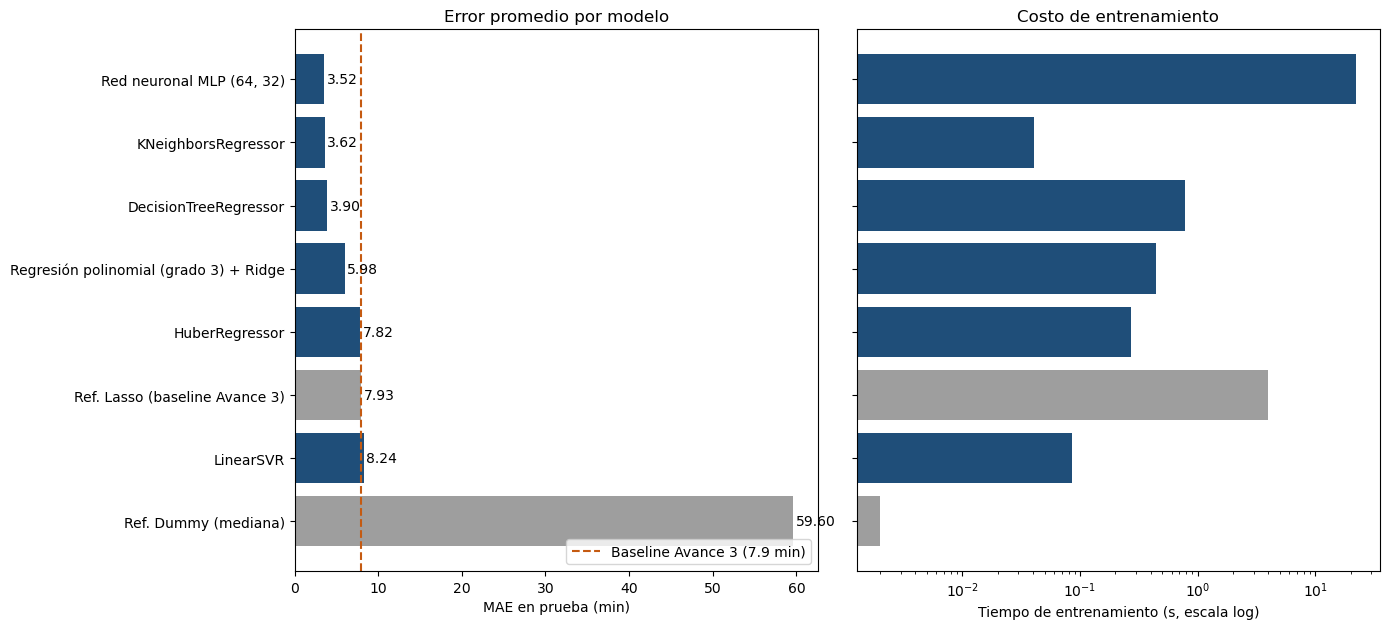

In [25]:
tabla = comparacion.sort_values("MAE_min", ascending=False)
baseline = comparacion.loc["Ref. Lasso (baseline Avance 3)", "MAE_min"]
colores = ["#9e9e9e" if m.startswith("Ref.") else "#1f4e79" for m in tabla.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 0.55 * len(tabla) + 2))

axes[0].barh(tabla.index, tabla["MAE_min"], color=colores)
axes[0].axvline(baseline, color="#c55a11", linestyle="--", label=f"Baseline Avance 3 ({baseline:.1f} min)")
axes[0].set_xlabel("MAE en prueba (min)")
axes[0].set_title("Error promedio por modelo")
axes[0].legend(loc="lower right")
for k, v in enumerate(tabla["MAE_min"]):
    axes[0].text(v + 0.3, k, f"{v:.2f}", va="center")

axes[1].barh(tabla.index, tabla["t_entrenamiento_s"], color=colores)
axes[1].set_xscale("log")
axes[1].set_xlabel("Tiempo de entrenamiento (s, escala log)")
axes[1].set_title("Costo de entrenamiento")
axes[1].set_yticklabels([])

plt.tight_layout()
plt.show()

## 7. Selección de los dos mejores modelos

Elegimos la **MLP** y **KNN**, que son los dos con menor MAE en prueba. Para decidir nos fijamos en esto:

- **Menor error.** La MLP (3.52 min) y KNN (3.62 min) también son los que tienen más viajes dentro de ±10 min (96.1 % y 94.0 %).
- **Diferencia con el tercero.** El árbol queda en 3.90 min, solo 0.28 min (unos 17 segundos) arriba de KNN. No es mucho, así que lo consideramos.
- **Tiempo de predicción de KNN.** Los 11 s son para 87 mil viajes, unos 125 microsegundos por viaje, así que para el ajuste no es un problema. Sí lo tomamos en cuenta al elegir el modelo final (sección 9), porque KNN se hace más lento entre más viajes guarda.
- **Sobreajuste.** Ninguna brecha es preocupante: MLP 1.02, árbol 0.87 y KNN 0.75 min, comparadas con errores de 3.5 a 3.9 min. La de la MLP es la más alta y por eso incluimos `alpha` en su búsqueda.

Descartamos el árbol aunque es el más rápido y más interpretable que la MLP, porque de los tres es el que más se equivoca. La interpretabilidad la retomamos en la sección 9.

In [27]:
candidatos = comparacion.loc[
    ["Red neuronal MLP (64, 32)", "KNeighborsRegressor", "DecisionTreeRegressor", "Ref. Lasso (baseline Avance 3)"],
    ["MAE_min", "dentro_10min_%", "brecha_MAE_min", "t_entrenamiento_s", "t_prediccion_s"],
].copy()
candidatos["microseg_por_viaje"] = candidatos["t_prediccion_s"] / len(X_test) * 1e6
candidatos["mejora_vs_baseline_%"] = (1 - candidatos["MAE_min"] / baseline) * 100
candidatos.round(3)

,MAE_min,dentro_10min_%,brecha_MAE_min,t_entrenamiento_s,t_prediccion_s,microseg_por_viaje,mejora_vs_baseline_%
modelo,,,,,,,
"Red neuronal MLP (64, 32)",3.517,96.088,1.017,22.266,0.034,0.390,55.674
KNeighborsRegressor,3.623,94.007,0.754,0.040,10.950,125.342,54.338
DecisionTreeRegressor,3.903,93.333,0.871,0.777,0.012,0.141,50.812
Ref. Lasso (baseline Avance 3),7.934,70.298,-0.030,3.962,0.008,0.094,0.000


## 8. Ajuste fino de hiperparámetros

Seguimos la idea de *Fine-Tune Your Model* de Géron (2022):

- Hacemos la búsqueda con 50 mil viajes de entrenamiento y validación cruzada de 3 particiones. El conjunto de prueba no se toca en la búsqueda.
- Con la mejor combinación volvemos a entrenar usando los 349,445 viajes con `registrar`, para poder compararla con la tabla de la sección 6.
- **MLP:** `RandomizedSearchCV` con 12 combinaciones de 108 posibles (3 arquitecturas, 2 activaciones, 3 valores de `alpha`, 3 tasas de aprendizaje y 2 tamaños de lote). Usamos búsqueda aleatoria porque probar las 108 tardaría 9 veces más.
- **KNN:** `GridSearchCV` con las 16 combinaciones de vecinos (5, 10, 15, 25), pesos (uniformes o por distancia) y métrica (Manhattan `p=1` o euclidiana `p=2`). Como entrena rápido, sí probamos todas.

In [29]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV

# La búsqueda se hace sobre 50 mil viajes para que sea rápida; el mejor modelo se reentrena con todos
idx = X_train.sample(50_000, random_state=SEMILLA).index
X_bus, y_bus = X_train.loc[idx], y_train.loc[idx]
kfold = KFold(n_splits=3, shuffle=True, random_state=SEMILLA)


def resumen_busqueda(busqueda):
    """Tabla de configuraciones probadas, ordenada por MAE de validación cruzada en minutos."""
    r = pd.DataFrame(busqueda.cv_results_)
    r["MAE_cv_min"] = -r["mean_test_score"] / 60
    r["desv_cv_min"] = r["std_test_score"] / 60
    columnas = [c for c in r.columns if c.startswith("param_")] + ["MAE_cv_min", "desv_cv_min", "mean_fit_time"]
    return r[columnas].sort_values("MAE_cv_min").round(3)

### 8.1 Red neuronal MLP

Movemos la arquitectura (cuántas capas y de qué tamaño), la activación, la regularización (`alpha`), la tasa de aprendizaje y el tamaño de lote.

In [31]:
espacio_mlp = {
    "regressor__hidden_layer_sizes": [(64, 32), (128, 64), (128, 64, 32)],
    "regressor__activation": ["relu", "tanh"],
    "regressor__alpha": [1e-5, 1e-4, 1e-3],
    "regressor__learning_rate_init": [3e-4, 1e-3, 3e-3],
    "regressor__batch_size": [200, 512],
}
busqueda_mlp = RandomizedSearchCV(crear_mlp(), espacio_mlp, n_iter=12, cv=kfold,
                                  scoring="neg_mean_absolute_error", n_jobs=-1, random_state=SEMILLA)
inicio = time.perf_counter()
busqueda_mlp.fit(X_bus, y_bus)
print(f"Tiempo de búsqueda: {time.perf_counter() - inicio:.0f} s")
print("Mejores hiperparámetros:", busqueda_mlp.best_params_)

# clone copia los mejores hiperparámetros sin el entrenamiento; registrar reentrena con los 349 mil viajes
mlp_ajustada = clone(busqueda_mlp.best_estimator_)
registrar("MLP ajustada", mlp_ajustada)
print("Épocas del modelo reentrenado:", mlp_ajustada.regressor_.n_iter_)
resumen_busqueda(busqueda_mlp)

Tiempo de búsqueda: 35 s
Mejores hiperparámetros: {'regressor__learning_rate_init': 0.003, 'regressor__hidden_layer_sizes': (64, 32), 'regressor__batch_size': 512, 'regressor__alpha': 1e-05, 'regressor__activation': 'relu'}
Épocas del modelo reentrenado: 22


,param_regressor__learning_rate_init,param_regressor__hidden_layer_sizes,param_regressor__batch_size,param_regressor__alpha,param_regressor__activation,MAE_cv_min,desv_cv_min,mean_fit_time
9,0.003,"(64, 32)",512,0.000,relu,3.087,0.038,2.447
0,0.003,"(128, 64)",200,0.000,tanh,3.136,0.130,6.398
4,0.003,"(128, 64, 32)",200,0.000,tanh,3.138,0.273,7.117
5,0.001,"(128, 64)",512,0.000,tanh,3.154,0.026,12.149
8,0.003,"(128, 64)",200,0.001,tanh,3.173,0.088,6.205
1,0.001,"(64, 32)",512,0.000,relu,3.191,0.031,3.785
2,0.001,"(128, 64)",200,0.000,relu,3.192,0.035,5.295
11,0.001,"(128, 64, 32)",200,0.000,tanh,3.201,0.143,6.176
3,0.003,"(64, 32)",512,0.000,tanh,3.263,0.078,3.501
6,0.000,"(128, 64)",512,0.000,relu,3.497,0.045,12.959


### 8.2 K vecinos más cercanos (KNN)

Movemos el número de vecinos, cómo se ponderan y la métrica de distancia. Si gana `weights="distance"`, el MAE de entrenamiento sale optimista porque cada viaje es su propio vecino más cercano, así que la brecha se infla sin que eso signifique sobreajuste. En ese caso nos guiamos por el MAE de prueba.

In [33]:
espacio_knn = {
    "n_neighbors": [5, 10, 15, 25],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}
busqueda_knn = GridSearchCV(KNeighborsRegressor(), espacio_knn, cv=kfold,
                            scoring="neg_mean_absolute_error", n_jobs=-1)
inicio = time.perf_counter()
busqueda_knn.fit(X_bus, y_bus)
print(f"Tiempo de búsqueda: {time.perf_counter() - inicio:.0f} s")
print("Mejores hiperparámetros:", busqueda_knn.best_params_)

knn_ajustado = clone(busqueda_knn.best_estimator_)
registrar("KNN ajustado", knn_ajustado)
resumen_busqueda(busqueda_knn)

Tiempo de búsqueda: 27 s
Mejores hiperparámetros: {'n_neighbors': 5, 'p': 2, 'weights': 'distance'}


,param_n_neighbors,param_p,param_weights,MAE_cv_min,desv_cv_min,mean_fit_time
3,5,2,distance,4.933,0.013,0.047
1,5,1,distance,5.018,0.015,0.053
7,10,2,distance,5.151,0.046,0.010
5,10,1,distance,5.179,0.039,0.009
2,5,2,uniform,5.205,0.007,0.044
0,5,1,uniform,5.319,0.006,0.042
6,10,2,uniform,5.710,0.052,0.014
9,15,1,distance,5.769,0.078,0.010
11,15,2,distance,5.788,0.073,0.012
4,10,1,uniform,5.893,0.048,0.009


### 8.3 Antes contra después del ajuste

Comparamos cada modelo ajustado contra su versión original, con el mismo conjunto de prueba.

In [35]:
pares = [("Red neuronal MLP (64, 32)", "MLP ajustada"), ("KNeighborsRegressor", "KNN ajustado")]
antes_despues = pd.DataFrame(resultados).set_index("modelo").loc[
    [m for par in pares for m in par],
    ["MAE_min", "RMSE_min", "dentro_10min_%", "brecha_MAE_min", "t_entrenamiento_s", "t_prediccion_s"],
]

for antes, despues in pares:
    a, d = antes_despues.loc[antes, "MAE_min"], antes_despues.loc[despues, "MAE_min"]
    print(f"{despues}: MAE de {a:.3f} a {d:.3f} min ({(d - a) / a * 100:+.1f} %), "
          f"{(1 - d / baseline) * 100:.1f} % menos que el baseline")

antes_despues.round(3)

MLP ajustada: MAE de 3.517 a 3.513 min (-0.1 %), 55.7 % menos que el baseline
KNN ajustado: MAE de 3.623 a 3.493 min (-3.6 %), 56.0 % menos que el baseline


,MAE_min,RMSE_min,dentro_10min_%,brecha_MAE_min,t_entrenamiento_s,t_prediccion_s
modelo,,,,,,
"Red neuronal MLP (64, 32)",3.517,4.583,96.088,1.017,22.266,0.034
MLP ajustada,3.513,4.626,95.703,1.014,15.865,0.068
KNeighborsRegressor,3.623,4.996,94.007,0.754,0.040,10.950
KNN ajustado,3.493,4.698,95.178,1.312,0.085,12.068


**Qué pasó con el ajuste:**

- **KNN mejoró 3.6 %** (3.623 a 3.493 min), su RMSE bajó de 5.00 a 4.70 min y los viajes dentro de ±10 min subieron de 94.0 % a 95.2 %. Ganó la combinación de 5 vecinos con pesos por distancia y métrica euclidiana: dar más peso a los viajes más parecidos ayudó más que agregar vecinos. La brecha subió a 1.31 min, pero es por los pesos por distancia (ver 8.2), no porque generalice peor, ya que el error de prueba bajó.
- **La MLP casi no cambió** (3.517 a 3.513 min) y su RMSE subió un poco (4.58 a 4.63). La configuración original ya estaba cerca de la mejor del espacio que probamos. En la búsqueda se ve que la tasa de aprendizaje es lo que más influye: con `3e-4` el MAE de validación sube a 3.5 a 4.9 min, porque con `early_stopping` la red se detiene antes de terminar de aprender.
- **Las dos mejores configuraciones quedaron en el borde del espacio de búsqueda:** la MLP con la `alpha` más baja (`1e-5`) y la tasa más alta (`3e-3`), y KNN con el menor número de vecinos (5). Eso indica que vale la pena ampliar la búsqueda hacia esos lados.

## 9. Modelo individual final

Además del error, comparamos los dos modelos ajustados en lo que importa para usar el ETA en operación: cuánto tarda en predecir **un solo viaje** (en producción el ETA se calcula viaje por viaje), cuánto pesa el modelo y qué tan estable es su error entre las particiones de la validación cruzada.

In [38]:
import pickle


def latencia_ms(modelo, repeticiones=200):
    """Tiempo promedio de predecir un solo viaje, como al calcular un ETA en producción."""
    viaje = X_test.iloc[[0]]
    modelo.predict(viaje)  # calentamiento
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        modelo.predict(viaje)
    return (time.perf_counter() - inicio) / repeticiones * 1000


def desv_cv_min(busqueda):
    """Desviación estándar del MAE entre particiones para la mejor configuración."""
    return busqueda.cv_results_["std_test_score"][busqueda.best_index_] / 60


finalistas = {"MLP ajustada": (mlp_ajustada, busqueda_mlp), "KNN ajustado": (knn_ajustado, busqueda_knn)}
tabla_final = pd.DataFrame(resultados).set_index("modelo").loc[
    list(finalistas), ["MAE_min", "RMSE_min", "dentro_10min_%", "dentro_15min_%", "brecha_MAE_min"]
].copy()
tabla_final["latencia_1_viaje_ms"] = [latencia_ms(m) for m, _ in finalistas.values()]
tabla_final["tamaño_modelo_MB"] = [len(pickle.dumps(m)) / 1e6 for m, _ in finalistas.values()]
tabla_final["desv_MAE_cv_min"] = [desv_cv_min(b) for _, b in finalistas.values()]
tabla_final.round(3)

,MAE_min,RMSE_min,dentro_10min_%,dentro_15min_%,brecha_MAE_min,latencia_1_viaje_ms,tamaño_modelo_MB,desv_MAE_cv_min
modelo,,,,,,,,
MLP ajustada,3.513,4.626,95.703,99.852,1.014,0.306,0.150,0.038
KNN ajustado,3.493,4.698,95.178,99.621,1.312,4.292,167.736,0.013


### Elección: MLP ajustada

| Criterio | MLP ajustada | KNN ajustado |
|---|---|---|
| MAE | 3.513 min | **3.493 min** (0.02 min menos, poco más de 1 segundo por viaje) |
| RMSE y errores grandes | **4.63 min**, 99.85 % dentro de ±15 min | 4.70 min, 99.62 % dentro de ±15 min |
| Predicción de un viaje | **0.30 ms** | 4.29 ms, unas 14 veces más lento, y crece conforme se guardan más viajes |
| Tamaño del modelo | **0.15 MB** (solo los pesos de la red) | 168 MB (guarda los 349 mil viajes) |
| Interpretabilidad | Caja negra | **Se puede explicar un ETA mostrando los viajes parecidos** |
| Estabilidad entre particiones | Desviación de 0.038 min | **0.013 min**, y siempre da la misma predicción con los mismos datos |

KNN ganó en MAE, pero por una diferencia muy chica: 0.02 min, poco más de un segundo por viaje. En cambio, la MLP comete menos errores grandes (menor RMSE y más viajes dentro de ±15 min), que son los que más afectan a operaciones porque un ETA muy equivocado es el que hace llegar tarde a un chofer.

Lo que decide es el uso en producción. El ETA se calcula viaje por viaje, y ahí la MLP es unas 14 veces más rápida y pesa más de mil veces menos. Además, el sistema va a ir acumulando viajes GPS todos los días: con KNN cada viaje nuevo haría la predicción más lenta y el modelo más pesado, mientras que la MLP solo necesita reentrenarse de vez en cuando.

Por eso nos quedamos con la **MLP ajustada**. Cedemos 1 segundo de MAE promedio y la interpretabilidad de KNN a cambio de menos errores grandes, rapidez y un modelo que no crece con los datos. Para recuperar algo de interpretabilidad, más adelante podemos usar importancia por permutación sobre la red, o mostrar en el tablero viajes parecidos como apoyo, sin usarlos para calcular el ETA.

## 10. Conclusiones


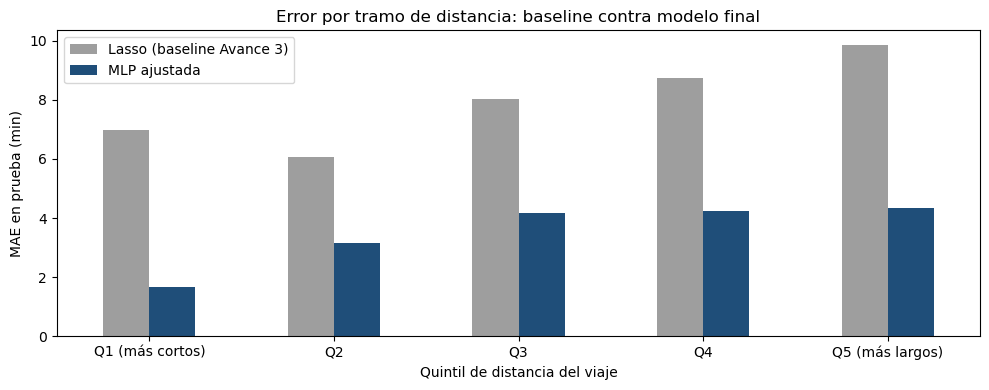

,Lasso (baseline Avance 3),MLP ajustada
tramo,,
Q1 (más cortos),6.97,1.67
Q2,6.07,3.15
Q3,8.04,4.18
Q4,8.75,4.24
Q5 (más largos),9.86,4.32


In [41]:
# Error por tramo de distancia: ¿el modelo final resolvió el subajuste del baseline?
lasso = Lasso(alpha=0.001, max_iter=2000, tol=1e-3).fit(X_train, y_train)

tramos = pd.qcut(X_test[COLUMNA_DISTANCIA], q=5,
                 labels=["Q1 (más cortos)", "Q2", "Q3", "Q4", "Q5 (más largos)"])
errores = pd.DataFrame({
    "tramo": tramos,
    "Lasso (baseline Avance 3)": np.abs(y_test.values - lasso.predict(X_test)) / 60,
    "MLP ajustada": np.abs(y_test.values - mlp_ajustada.predict(X_test)) / 60,
})
mae_tramo = errores.groupby("tramo", observed=True).mean()

ax = mae_tramo.plot(kind="bar", figsize=(10, 4), color=["#9e9e9e", "#1f4e79"], rot=0)
ax.set_xlabel("Quintil de distancia del viaje")
ax.set_ylabel("MAE en prueba (min)")
ax.set_title("Error por tramo de distancia: baseline contra modelo final")
plt.tight_layout()
plt.show()

mae_tramo.round(2)

1. **Los modelos no lineales sí resolvieron el subajuste del Avance 3.** La MLP, KNN y el árbol bajaron el MAE de 7.93 min a entre 3.5 y 3.9 min, casi la mitad, y los viajes dentro de ±10 min pasaron de 70 % a más de 93 %. En la gráfica por tramos se ve que el baseline en general empeoraba (de 7.0 a 9.9 min); la MLP ajustada baja el error en todos los tramos, sobre todo en los viajes más cortos (de 7.0 a 1.7 min) y en los más largos (de 9.9 a 4.3 min).

2. **Los lineales confirman lo que vimos en el Avance 3.** Huber (7.82 min) y LinearSVR (8.24 min) quedaron igual que el baseline, y la polinomial (5.98 min) mejoró solo a medias. El problema era la forma del modelo, no los valores atípicos.

3. **Ajuste fino.** KNN mejoró 3.6 % (3.62 a 3.49 min) con pesos por distancia. La MLP casi no cambió (3.52 a 3.51 min), porque su configuración original ya estaba cerca de la mejor que probamos.

4. **Modelo final: MLP ajustada.** KNN quedó 0.02 min abajo en MAE, pero la MLP tiene menos errores grandes, predice un viaje 14 veces más rápido y pesa 0.15 MB contra 168 MB, y no crece con los datos. Perdemos interpretabilidad frente a KNN.

5. **Lo que sigue:**
   - Probar ensambles en el Avance 5 (bosques aleatorios, XGBoost, LightGBM). Si un solo árbol quedó a 0.4 min de la MLP, varios árboles juntos podrían superarla.
   - Ampliar la búsqueda de la MLP hacia `alpha` más bajas y tasas de aprendizaje más altas, porque la mejor configuración quedó en el borde del espacio.
   - Probar el modelo con viajes reales de los GPS de Feraltar (piloto con Traccar) antes de usar el ETA en operación, porque pueden comportarse distinto que los datos de este avance.

## 11. Bibliografía

- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., y Plöd, M. (2023). *CRISP-ML(Q). The ML Lifecycle Process*. MLOps. INNOQ. https://ml-ops.org/content/crisp-ml

## 12. Declaración sobre el uso de herramientas de inteligencia artificial

**Herramienta utilizada:** Claude (Anthropic), asistente conversacional.

### Uso de inteligencia artificial

Usamos Claude para:

- Proponer la estructura del notebook, la función `registrar`.
- Generar el código de la regresión polinomial (5.1), la red neuronal MLP (5.5) y la búsqueda de hiperparámetros (sección 8), que el equipo revisó, ejecutó y adaptó.
- Explicar conceptos (detención temprana, búsqueda aleatoria contra búsqueda en rejilla, pesos por distancia en KNN) y resolver dudas puntuales del entorno.


Revisamos, ejecutamos y validamos el código y los resultados, y las decisiones del avance son del equipo.

**Referencia:**
Anthropic. (2026). *Claude* (versión Opus 5.5) [Modelo de lenguaje grande]. https://claude.ai

### Contribución de cada integrante

| Integrante | Contribución |
|---|---|
| Alejandra Guadalupe Larrañaga Altamirano | Integración del notebook, regresión polinomial y red neuronal MLP, ajuste fino y revisión de los textos |
| Mario Alberto Guillén | Árbol de decisión y K vecinos más cercanos |
| Andrea Kimberly Fray Tamayo |  Máquina de soporte vectorial (LinearSVR) y regresión robusta Huber  |

### Decisiones del equipo y alternativas descartadas

1. **Entrenar LinearSVR y Huber con una muestra de 50 mil viajes.** *Alternativa descartada:* SVR con kernel RBF sobre los 349 mil viajes, cuyo costo crece aproximadamente con el cuadrado del número de datos.
2. **Ajustar hiperparámetros con validación cruzada sobre 50 mil viajes y reentrenar la mejor configuración con todos.** *Alternativa descartada:* hacer la búsqueda sobre el conjunto completo, varias veces más lenta; con la muestra, cada búsqueda toma minutos y el resultado final se mide igual sobre los 349 mil viajes.
3. **Elegir la MLP ajustada como modelo individual final.** *Alternativa descartada:* KNN ajustado, que tuvo un MAE 0.02 min menor y es más interpretable, pero predice un viaje 14 veces más lento, pesa 168 MB y crece con cada viaje que se agrega a los datos.